In [31]:
import pandas as pd
from sqlalchemy import create_engine

# Below we specify the parameters required to access the db.
host = "localhost"
user = "root"
password = ""
database = "milk_collection_db"

# Create a connection to the db.
connection = f"mysql+pymysql://{user}:{password}@{host}/{database}"

# By use of sql alchemy engine, establish the connection.
engine = create_engine(connection)

# Specify the query you want to execute.
query = """SELECT f.first_name AS farmer_first_name, f.last_name as farmer_last_name, p.amount, p.payment_date, p.status, c.litres * c.price_per_litre as Exact_amout_paid, c.litres, c.price_per_litre, po.first_name AS porter_first_name, po.last_name as porter_last_name FROM farmers f INNER JOIN payments p ON f.farmer_id = p.farmers_id INNER JOIN collections c ON f.farmer_id = c.farmer_id INNER JOIN porters po ON c.porter_id = po.porter_id"""

# Create a dataframe after the query has executed.
df = pd.read_sql_query(query, engine)

# Print out the dataframe.
df

,farmer_first_name,farmer_last_name,amount,payment_date,status,Exact_amout_paid,litres,price_per_litre,porter_first_name,porter_last_name
0,Brian,Ollum,5370.0,2026-10-01,PAID,4708.60,72.44,65.0,Martin,Musembi
1,Brian,Ollum,5370.0,2026-10-01,PAID,3835.00,59.00,65.0,Hadassah,Halima
2,Onesmus,Maitha,6723.0,2026-10-02,PAID,2802.80,43.12,65.0,Martin,Musembi
3,Onesmus,Maitha,6723.0,2026-10-02,PAID,4046.25,62.25,65.0,Hadassah,Halima
4,Maria,Terry,4981.0,2026-10-03,PENDING,3299.40,50.76,65.0,Martin,Musembi
5,Maria,Terry,4981.0,2026-10-03,PENDING,3237.00,49.80,65.0,Raphael,Lisbon
6,Michael,Tsuma,5519.0,2026-10-04,PAID,2537.60,39.04,65.0,Martin,Musembi
7,Michael,Tsuma,5519.0,2026-10-04,PAID,4145.70,63.78,65.0,Raphael,Lisbon
8,Emmanuel,Kukat,6819.0,2026-10-05,PAID,3153.80,48.52,65.0,Malik,Mwangi
9,Emmanuel,Kukat,6819.0,2026-10-05,PAID,5697.90,87.66,65.0,Raphael,Lisbon


In [32]:
# Finding the shape of our dataframe.
df.shape

(20, 10)

In [33]:
# Check for some info in regard to the generated df.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   farmer_first_name  20 non-null     str    
 1   farmer_last_name   20 non-null     str    
 2   amount             20 non-null     float64
 3   payment_date       20 non-null     object 
 4   status             20 non-null     str    
 5   Exact_amout_paid   20 non-null     float64
 6   litres             20 non-null     float64
 7   price_per_litre    20 non-null     float64
 8   porter_first_name  20 non-null     str    
 9   porter_last_name   20 non-null     str    
dtypes: float64(4), object(1), str(5)
memory usage: 1.7+ KB


In [34]:
# Summary statistics for numeric columns.
df.describe()

,amount,Exact_amout_paid,litres,price_per_litre
count,20.000000,20.000000,20.000000,20.0
mean,6483.000000,4206.572500,64.716500,65.0
std,1046.377209,1303.475169,20.053464,0.0
min,4981.000000,2537.600000,39.040000,65.0
25%,5519.000000,3216.200000,49.480000,65.0
50%,6687.500000,3886.675000,59.795000,65.0
75%,7041.000000,4848.837500,74.597500,65.0
max,8360.000000,7330.050000,112.770000,65.0


In [35]:
# Below is how we export thr entire df into a csv.
df.to_csv("milk_collection_data.csv", index=False)

In [36]:
# Create a db table from an existing data frame.
df.to_sql("collection_summary", engine, if_exists="replace", index=False)

20

In [37]:
# Check missing and duplicate values.
print(df.isnull().sum())
print("Duplicate rows: ", df.duplicated().sum())

farmer_first_name    0
farmer_last_name     0
amount               0
payment_date         0
status               0
Exact_amout_paid     0
litres               0
price_per_litre      0
porter_first_name    0
porter_last_name     0
dtype: int64
Duplicate rows:  0


In [38]:
# Clean up and create helper columns.
# Fix the column name typo, build full names and convert the date column.
df = df.rename(columns={"Exact_amount_paid" : "Exact_amount"})
df["farmer"] = df["farmer_first_name"] + " " + df["farmer_last_name"]
df["porter"] = df["porter_first_name"] + " " + df["porter_last_name"]
df["payment_date"] = pd.to_datetime(df["payment_date"])
df

,farmer_first_name,farmer_last_name,amount,payment_date,status,Exact_amout_paid,litres,price_per_litre,porter_first_name,porter_last_name,farmer,porter
0,Brian,Ollum,5370.0,2026-10-01,PAID,4708.60,72.44,65.0,Martin,Musembi,Brian Ollum,Martin Musembi
1,Brian,Ollum,5370.0,2026-10-01,PAID,3835.00,59.00,65.0,Hadassah,Halima,Brian Ollum,Hadassah Halima
2,Onesmus,Maitha,6723.0,2026-10-02,PAID,2802.80,43.12,65.0,Martin,Musembi,Onesmus Maitha,Martin Musembi
3,Onesmus,Maitha,6723.0,2026-10-02,PAID,4046.25,62.25,65.0,Hadassah,Halima,Onesmus Maitha,Hadassah Halima
4,Maria,Terry,4981.0,2026-10-03,PENDING,3299.40,50.76,65.0,Martin,Musembi,Maria Terry,Martin Musembi
5,Maria,Terry,4981.0,2026-10-03,PENDING,3237.00,49.80,65.0,Raphael,Lisbon,Maria Terry,Raphael Lisbon
6,Michael,Tsuma,5519.0,2026-10-04,PAID,2537.60,39.04,65.0,Martin,Musembi,Michael Tsuma,Martin Musembi
7,Michael,Tsuma,5519.0,2026-10-04,PAID,4145.70,63.78,65.0,Raphael,Lisbon,Michael Tsuma,Raphael Lisbon
8,Emmanuel,Kukat,6819.0,2026-10-05,PAID,3153.80,48.52,65.0,Malik,Mwangi,Emmanuel Kukat,Malik Mwangi
9,Emmanuel,Kukat,6819.0,2026-10-05,PAID,5697.90,87.66,65.0,Raphael,Lisbon,Emmanuel Kukat,Raphael Lisbon


In [39]:
# Understand what one row means.
# Each row is one collection, but amount(payment) is repeated on every row for the same farmer.
#Check how many different payments/values each farmer has.
df.groupby("farmer").agg(
    collections=("litres", "size"),
    distinct_payment_values=("amount", "nunique"),
    payment_dates=("payment_date", "nunique"),
)

,collections,distinct_payment_values,payment_dates
farmer,,,
Balvin Brown,2,1,1
Brian Ollum,2,1,1
Collins Mutitu,2,1,1
Emmanuel Kukat,2,1,1
Lavendar Simbisa,2,1,1
Lawrence Ogutu,2,1,1
Lydia Aseka,2,1,1
Maria Terry,2,1,1
Michael Tsuma,2,1,1


In [40]:
# The sum of the amount that was paid to the farmers wrongly against the sum of the correct amount that was to be paid to the farmers.
payments = df.drop_duplicates(subset=["farmer", "amount"])[["farmer", "amount", "payment_date"]]
print("Total amount to be paid: ", payments["amount"].sum())
print("wrong total if you sum the amount: ", df["amount"].sum())
print("The difference of the figures is: ", df["amount"].sum() - payments["amount"].sum())

Total amount to be paid:  64830.0
wrong total if you sum the amount:  129660.0
The difference of the figures is:  64830.0


In [41]:
# The number of collections handled by each and every porter.
df.groupby("porter_first_name").size()

porter_first_name
Abigael     4
Hadassah    4
Malik       4
Martin      4
Raphael     4
dtype: int64

/var/folders/88/w28ml11d1vs7z6sxcrh2qjdc0000gn/T/ipykernel_45013/567220646.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="porter", data = df, palette="spring")


Text(0.5, 0, 'Name of the porter')

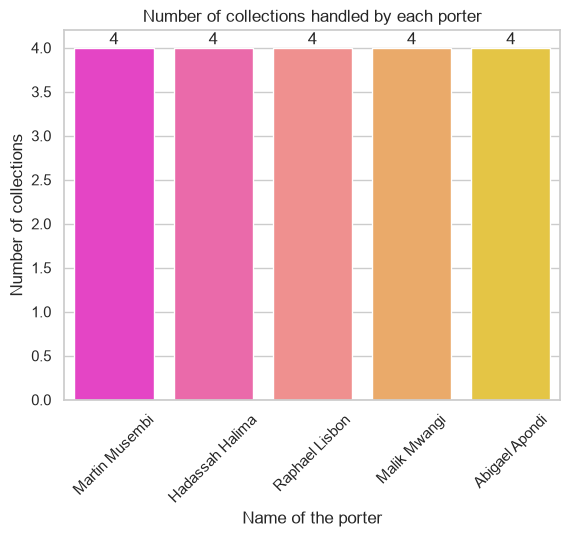

In [42]:
# The above info can be presented on a countplot as shown below.
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

ax = sns.countplot(x="porter", data = df, palette="spring")
#Below we give the exact number for each bar.
for container in ax.containers:
    ax.bar_label(container)
#Below we are rotating the names so that they do not overlap each other.
plt.xticks(rotation=45)
plt.title("Number of collections handled by each porter")
plt.ylabel("Number of collections")
plt.xlabel("Name of the porter")

In [43]:
# The number of collections that happened to each farmer.
df.groupby("farmer_first_name").size()

farmer_first_name
Balvin      2
Brian       2
Collins     2
Emmanuel    2
Lavendar    2
Lawrence    2
Lydia       2
Maria       2
Michael     2
Onesmus     2
dtype: int64

/var/folders/88/w28ml11d1vs7z6sxcrh2qjdc0000gn/T/ipykernel_45013/3907147696.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(y="farmer", data = df, palette="autumn")


Text(0, 0.5, 'Name of the farmer')

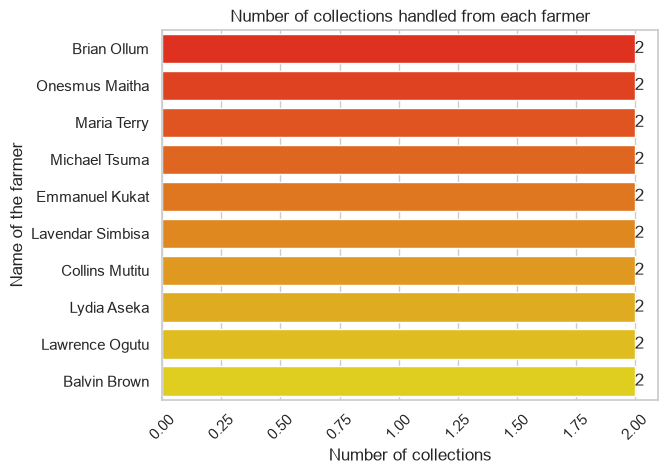

In [44]:
# Have a visual of the number of collections that happened to each farmer.
ax = sns.countplot(y="farmer", data = df, palette="autumn")
#Below we give the exact number for each bar.
for container in ax.containers:
    ax.bar_label(container)
#Below we are rotating the names so that they do not overlap each other.
plt.xticks(rotation=45)
plt.title("Number of collections handled from each farmer")
plt.xlabel("Number of collections")
plt.ylabel("Name of the farmer")

Text(0, 0.5, 'Total count')

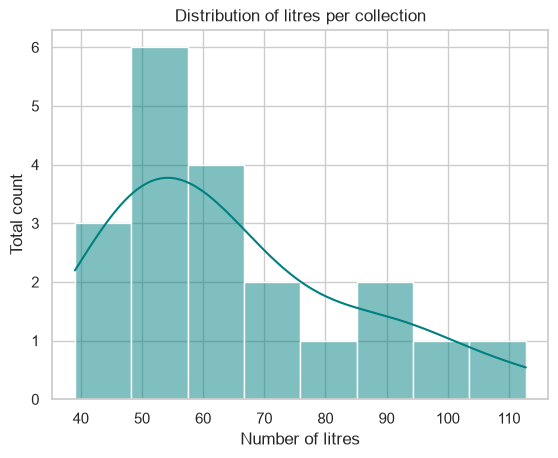

In [45]:
# The distribution of litres per colection.
sns.histplot(df["litres"], bins=8, kde=True, color="Teal")
plt.title("Distribution of litres per collection")
plt.xlabel("Number of litres")
plt.ylabel("Total count")

Text(0.5, 1.0, 'Share of litres collected by each porter')

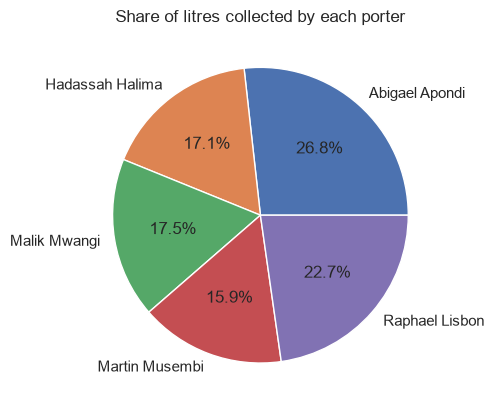

In [47]:
# Visualize what each and every porter was able to deliver using a piechart.
df.groupby("porter")["litres"].sum().plot.pie(autopct="%1.1f%%")
plt.title("Share of litres collected by each porter")

Text(0.5, 1.0, 'Percentage of litres supplied by each farmer')

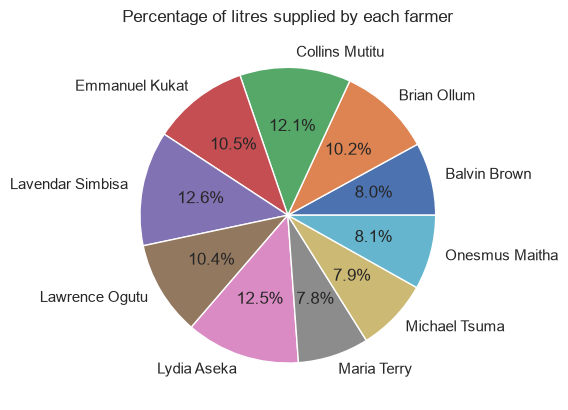

In [48]:
# Visualize how many litres each and every farmer was able to deliver using a piechart.
df.groupby("farmer")["litres"].sum().plot.pie(autopct="%1.1f%%")
plt.title("Percentage of litres supplied by each farmer")

/var/folders/88/w28ml11d1vs7z6sxcrh2qjdc0000gn/T/ipykernel_45013/1145686464.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = "litres", y = "farmer", data = farmer_litres, palette = "Blues")


Text(0, 0.5, "Farmer's name")

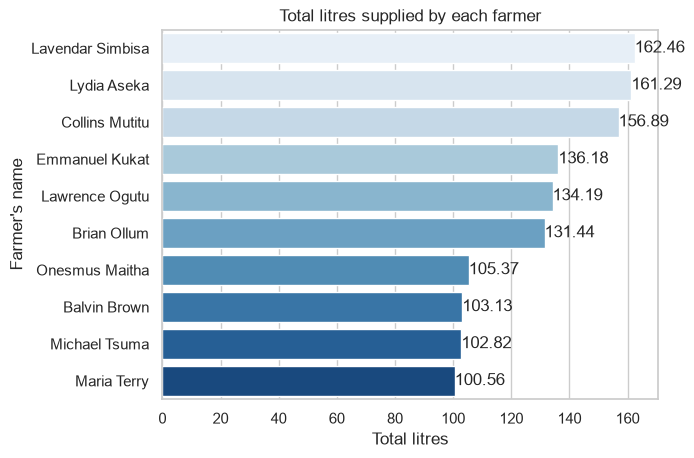

In [55]:
# Total litres supplied by each farmer.
farmer_litres = df.groupby("farmer")["litres"].sum().sort_values(ascending=False).reset_index()

ax = sns.barplot(x = "litres", y = "farmer", data = farmer_litres, palette = "Blues")
ax

for container in ax.containers:
    ax.bar_label(container)

plt.title("Total litres supplied by each farmer")
plt.xlabel("Total litres")
plt.ylabel("Farmer's name")